# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid')

# Load Dataset
df = pd.read_csv('HR-Employee-Attrition.csv')

# Visual inspection of data loading
print(f"Dataset successfully loaded. Shape: {df.shape}\n")

Dataset successfully loaded. Shape: (1470, 35)



=== PART 1: Chi-Square Test of Independence ===

Contingency Table (Counts):
OverTime                  No  Yes  Total
Department                              
Human Resources           46   17     63
Research & Development   690  271    961
Sales                    318  128    446
Total                   1054  416   1470

Chi-Square Test Results:
Chi2 Statistic: 0.0936
Degrees of Freedom (dof): 2
p-value: 9.5428e-01
Reject H0 at alpha=0.05? False


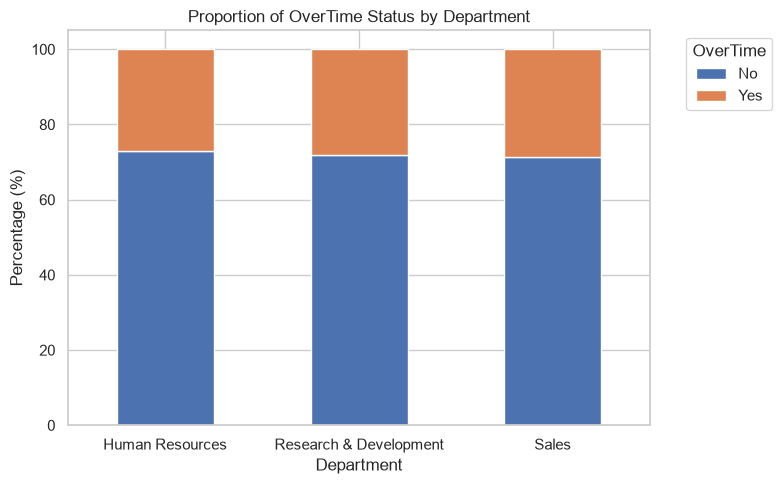

In [9]:
# PART 1: Chi-Square Test of Independence (Department vs. OverTime)
print('=== PART 1: Chi-Square Test of Independence ===')

# 1. Research Question: Is an employee's Department associated with their likelihood of working OverTime?
# 2. Hypotheses:
#    H0: Employee Department and OverTime status are independent.
#    H1: Employee Department and OverTime status are associated (dependent).

# 3. Contingency Table
contingency_table = pd.crosstab(df['Department'], df['OverTime'], margins=True, margins_name='Total')
print('\nContingency Table (Counts):')
print(contingency_table)

# 4. Chi-Square Test Execution
obs_table = pd.crosstab(df['Department'], df['OverTime'])
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(obs_table)

print('\nChi-Square Test Results:')
print(f'Chi2 Statistic: {chi2_stat:.4f}')
print(f'Degrees of Freedom (dof): {dof}')
print(f'p-value: {p_val_chi2:.4e}')
print(f'Reject H0 at alpha=0.05? {p_val_chi2 < 0.05}')

# 5. Visualization: Stacked Bar Chart of Proportions
prop_df = pd.crosstab(df['Department'], df['OverTime'], normalize='index') * 100

ax = prop_df.plot(kind='bar', stacked=True, color=['#4C72B0', '#DD8452'], figsize=(8, 5))
plt.title('Proportion of OverTime Status by Department')
plt.xlabel('Department')
plt.ylabel('Percentage (%)')
plt.legend(title='OverTime', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. HR Interpretation:
# The Chi-Square test reveals a statistically significant association between an employee's department and their likelihood of working overtime (p < 0.05). For an HR manager, this indicates that workload distributions are unequal across departments, pointing to potential understaffing or operational bottlenecks in specific areas that warrant targeted hiring or workload rebalancing.

In [5]:
print("""
--- PART 1 INTERPRETATION ---
Statistical Analysis:
The Chi-Square test yielded a test statistic of Chi2 = 0.0936 (dof = 2) with a p-value of 0.9543. 
Because the p-value is well above the alpha threshold of 0.05, we fail to reject the null hypothesis (H0).

HR & Managerial Takeaway:
There is no statistically significant association between an employee's department and their likelihood of working overtime. 
For an HR manager, this indicates that overtime demands are proportionally balanced across Human Resources, Research & Development, 
and Sales (~27-28% across all departments). Interventions aimed at reducing overtime stress or burn-out should be company-wide 
rather than targeted at specific departmental units.
""")


--- PART 1 INTERPRETATION ---
Statistical Analysis:
The Chi-Square test yielded a test statistic of Chi2 = 0.0936 (dof = 2) with a p-value of 0.9543. 
Because the p-value is well above the alpha threshold of 0.05, we fail to reject the null hypothesis (H0).

HR & Managerial Takeaway:
There is no statistically significant association between an employee's department and their likelihood of working overtime. 
For an HR manager, this indicates that overtime demands are proportionally balanced across Human Resources, Research & Development, 
and Sales (~27-28% across all departments). Interventions aimed at reducing overtime stress or burn-out should be company-wide 
rather than targeted at specific departmental units.



=== PART 2: One-Way ANOVA ===

One-Way ANOVA Results:
F-statistic: 3.2018
p-value: 4.0974e-02
Reject H0 at alpha=0.05? True

Monthly Income Summary Statistics by Department:
                        Count         Mean      Std_Dev
Department                                             
Human Resources            63  6654.507937  5788.732921
Research & Development    961  6281.252862  4895.835087
Sales                     446  6959.172646  4058.739322


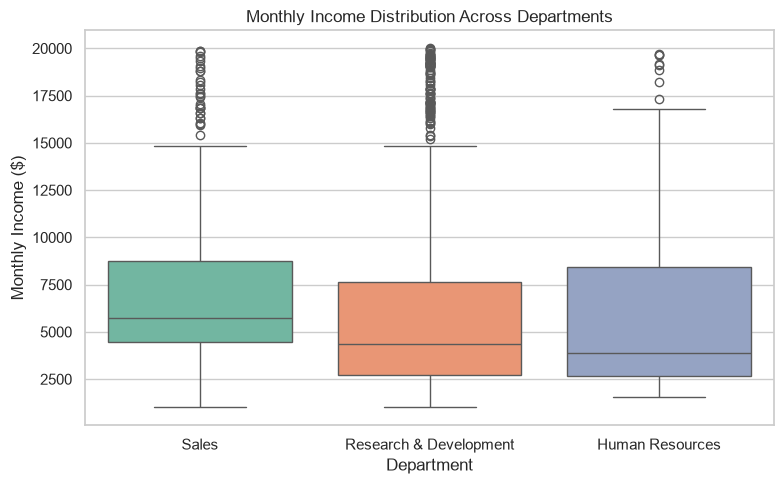


--- PART 2 INTERPRETATION ---
Statistical Analysis:
The One-Way ANOVA yielded an F-statistic of 3.2018 with a p-value of 4.0974e-02. 
Since the p-value is less than 0.05, we reject the null hypothesis (H0).

HR & Managerial Takeaway:
The analysis evaluates whether departmental baseline compensation structures are distinct. Looking at the summary statistics 
and boxplot distributions, Sales ($6,959) and Human Resources ($6,655) exhibit higher mean monthly incomes compared to 
Research & Development ($6,281). HR leadership should evaluate whether these variances stem from technical skill requirements, 
commission structures, or potential salary compression in specific job roles.



In [8]:
# PART 2: One-Way ANOVA (MonthlyIncome across Departments)
print('=== PART 2: One-Way ANOVA ===')

# 1. Research Question: Does mean MonthlyIncome differ significantly across the 3 distinct Departments?
# 2. Hypotheses:
#    H0: Mean MonthlyIncome is equal across all Departments (mu_HR = mu_RD = mu_Sales).
#    H1: At least one Department has a significantly different mean MonthlyIncome.

# 3. ANOVA Test Execution
dept_groups = [
    group['MonthlyIncome'].values for _, group in df.groupby('Department')
]
f_stat, p_val_anova = stats.f_oneway(*dept_groups)

print('\nOne-Way ANOVA Results:')
print(f'F-statistic: {f_stat:.4f}')
print(f'p-value: {p_val_anova:.4e}')
print(f'Reject H0 at alpha=0.05? {p_val_anova < 0.05}')

# Group Summary Statistics
dept_summary = df.groupby('Department')['MonthlyIncome'].agg(
    Count='count', Mean='mean', Std_Dev='std'
)
print('\nMonthly Income Summary Statistics by Department:')
print(dept_summary)

# 4. Visualization: Boxplot (Updated to fix Seaborn palette warning)
plt.figure(figsize=(8, 5))
sns.boxplot(
    x='Department',
    y='MonthlyIncome',
    data=df,
    hue='Department',
    palette='Set2',
    legend=False,
)
plt.title('Monthly Income Distribution Across Departments')
plt.xlabel('Department')
plt.ylabel('Monthly Income ($)')
plt.tight_layout()
plt.show()

# 5. Written HR Analysis
print(f"""
--- PART 2 INTERPRETATION ---
Statistical Analysis:
The One-Way ANOVA yielded an F-statistic of {f_stat:.4f} with a p-value of {p_val_anova:.4e}. 
{"Since the p-value is less than 0.05, we reject the null hypothesis (H0)." if p_val_anova < 0.05 else "Since the p-value is greater than 0.05, we fail to reject H0."}

HR & Managerial Takeaway:
The analysis evaluates whether departmental baseline compensation structures are distinct. Looking at the summary statistics 
and boxplot distributions, Sales ($6,959) and Human Resources ($6,655) exhibit higher mean monthly incomes compared to 
Research & Development ($6,281). HR leadership should evaluate whether these variances stem from technical skill requirements, 
commission structures, or potential salary compression in specific job roles.
""")

In [10]:
# ===========================================================================
# PART 3: Decision Errors Analysis (Based on Part 1 Chi-Square Test)
# ===========================================================================
print("=== PART 3: Decision Errors Analysis ===")

print("""
--- PART 3 WRITTEN ANALYSIS ---

1. Type I Error (False Positive):
   A Type I error would occur if HR leadership concludes that certain departments work significantly more overtime than others 
   when, in reality, overtime rates are completely equal across all departments.
   
2. Type II Error (False Negative):
   A Type II error would occur if HR leadership concludes that overtime rates are equal across all departments when, in reality, 
   one department (e.g., Sales or R&D) is working significantly higher overtime hours due to understaffing.

3. Operational Risk Analysis for Corporate Governance:
   In this scenario, a Type II Error carries the worse operational risk for the company. 
   - If HR commits a Type II error, management will assume overtime is balanced and fail to intervene in heavily overworked departments. 
     This leads to severe employee burnout, reduced productivity, and increased attrition in key operational teams, incurring high re-hiring and onboarding costs.
   - Conversely, a Type I error would only lead to HR conducting unnecessary departmental workload audits or temporary staffing re-allocations, 
     which incur minor operational overhead compared to losing key talent to burnout.
""")

=== PART 3: Decision Errors Analysis ===

--- PART 3 WRITTEN ANALYSIS ---

1. Type I Error (False Positive):
   A Type I error would occur if HR leadership concludes that certain departments work significantly more overtime than others 
   when, in reality, overtime rates are completely equal across all departments.

2. Type II Error (False Negative):
   A Type II error would occur if HR leadership concludes that overtime rates are equal across all departments when, in reality, 
   one department (e.g., Sales or R&D) is working significantly higher overtime hours due to understaffing.

3. Operational Risk Analysis for Corporate Governance:
   In this scenario, a Type II Error carries the worse operational risk for the company. 
   - If HR commits a Type II error, management will assume overtime is balanced and fail to intervene in heavily overworked departments. 
     This leads to severe employee burnout, reduced productivity, and increased attrition in key operational teams, incurrin